### Confusion Matrix

1. Classification Accuracy = (TP+TN)/(TP+TN+FP+FN)
2. Misclassification rate (Error rate) = (FP+FN)/(TP+TN+FP+FN)
3. Precision = TP/Total true Prediction = TP/(TP+TN) (when the model predict true class, how often was it right?)
4. Recall = TP/Actual = TP(TP+FN) (When the class was actually TRUE, how oftern did the classifier get it right?)


STEP # 1 : IMPORT LIBRARIES

In [27]:
import tensorflow as tf
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

STEP # 2 : IMPORT DATASET

In [28]:
df_alexa = pd.read_csv("amazon_alexa.tsv", sep="\t")
df_alexa


,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer...",1
3,5,31-Jul-18,Charcoal Fabric,I have had a lot of fun with this thing. My 4 ...,1
4,5,31-Jul-18,Charcoal Fabric,Music,1
...,...,...,...,...,...
3145,5,30-Jul-18,Black Dot,"Perfect for kids, adults and everyone in betwe...",1
3146,5,30-Jul-18,Black Dot,"Listening to music, searching locations, check...",1
3147,5,30-Jul-18,Black Dot,"I do love these things, i have them running my...",1
3148,5,30-Jul-18,White Dot,Only complaint I have is that the sound qualit...,1


In [29]:
df_alexa.head(5)

,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer...",1
3,5,31-Jul-18,Charcoal Fabric,I have had a lot of fun with this thing. My 4 ...,1
4,5,31-Jul-18,Charcoal Fabric,Music,1


STEP 3 : VISUALIZE DATASET

In [30]:
postive = df_alexa[df_alexa['feedback'] == 1]
postive

,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"Sometimes while playing a game, you can answer...",1
3,5,31-Jul-18,Charcoal Fabric,I have had a lot of fun with this thing. My 4 ...,1
4,5,31-Jul-18,Charcoal Fabric,Music,1
...,...,...,...,...,...
3145,5,30-Jul-18,Black Dot,"Perfect for kids, adults and everyone in betwe...",1
3146,5,30-Jul-18,Black Dot,"Listening to music, searching locations, check...",1
3147,5,30-Jul-18,Black Dot,"I do love these things, i have them running my...",1
3148,5,30-Jul-18,White Dot,Only complaint I have is that the sound qualit...,1


In [31]:
negative = df_alexa[df_alexa['feedback'] == 0]
negative

,rating,date,variation,verified_reviews,feedback
46,2,30-Jul-18,Charcoal Fabric,"It's like Siri, in fact, Siri answers more acc...",0
111,2,30-Jul-18,Charcoal Fabric,Sound is terrible if u want good music too get...,0
141,1,30-Jul-18,Charcoal Fabric,Not much features.,0
162,1,30-Jul-18,Sandstone Fabric,"Stopped working after 2 weeks ,didn't follow c...",0
176,2,30-Jul-18,Heather Gray Fabric,Sad joke. Worthless.,0
...,...,...,...,...,...
3047,1,30-Jul-18,Black Dot,Echo Dot responds to us when we aren't even ta...,0
3048,1,30-Jul-18,White Dot,NOT CONNECTED TO MY PHONE PLAYLIST :(,0
3067,2,30-Jul-18,Black Dot,The only negative we have on this product is t...,0
3091,1,30-Jul-18,Black Dot,I didn’t order it,0


<Axes: xlabel='feedback', ylabel='count'>

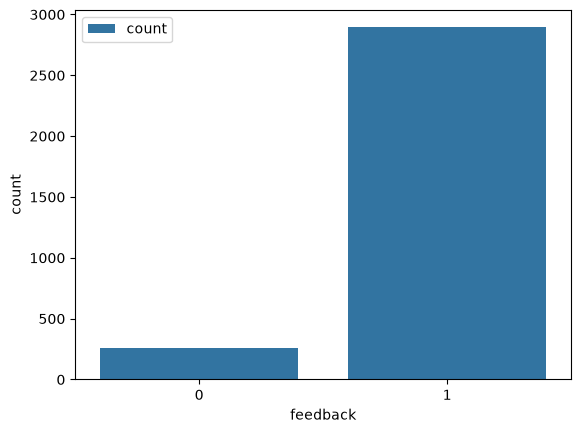

In [32]:
sns.countplot(x=df_alexa['feedback'], label = 'count')



<Axes: xlabel='rating', ylabel='count'>

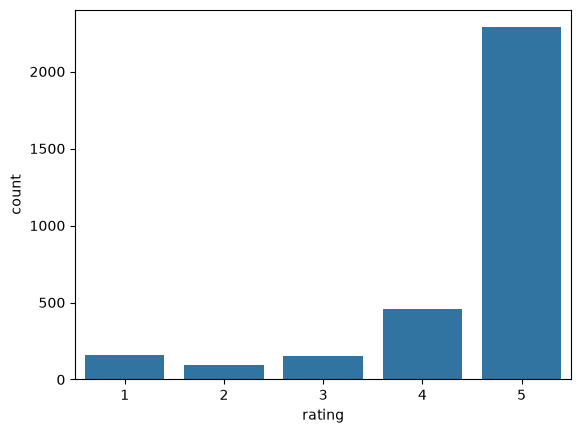

In [33]:
sns.countplot(x=df_alexa['rating'])

<Axes: >

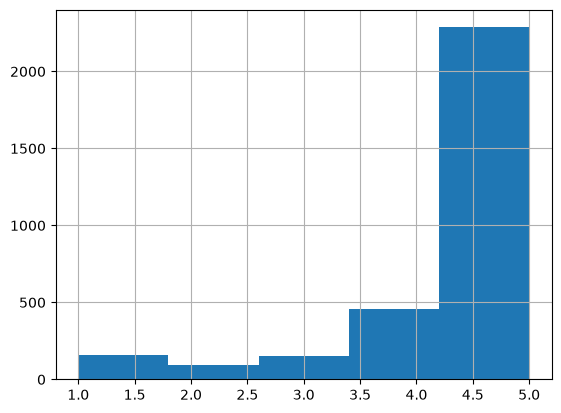

In [34]:
df_alexa['rating'].hist(bins = 5)

C:\Users\nmadan\AppData\Local\Temp\ipykernel_25204\1318834396.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_alexa['variation'], y=df_alexa['rating'],palette='deep')


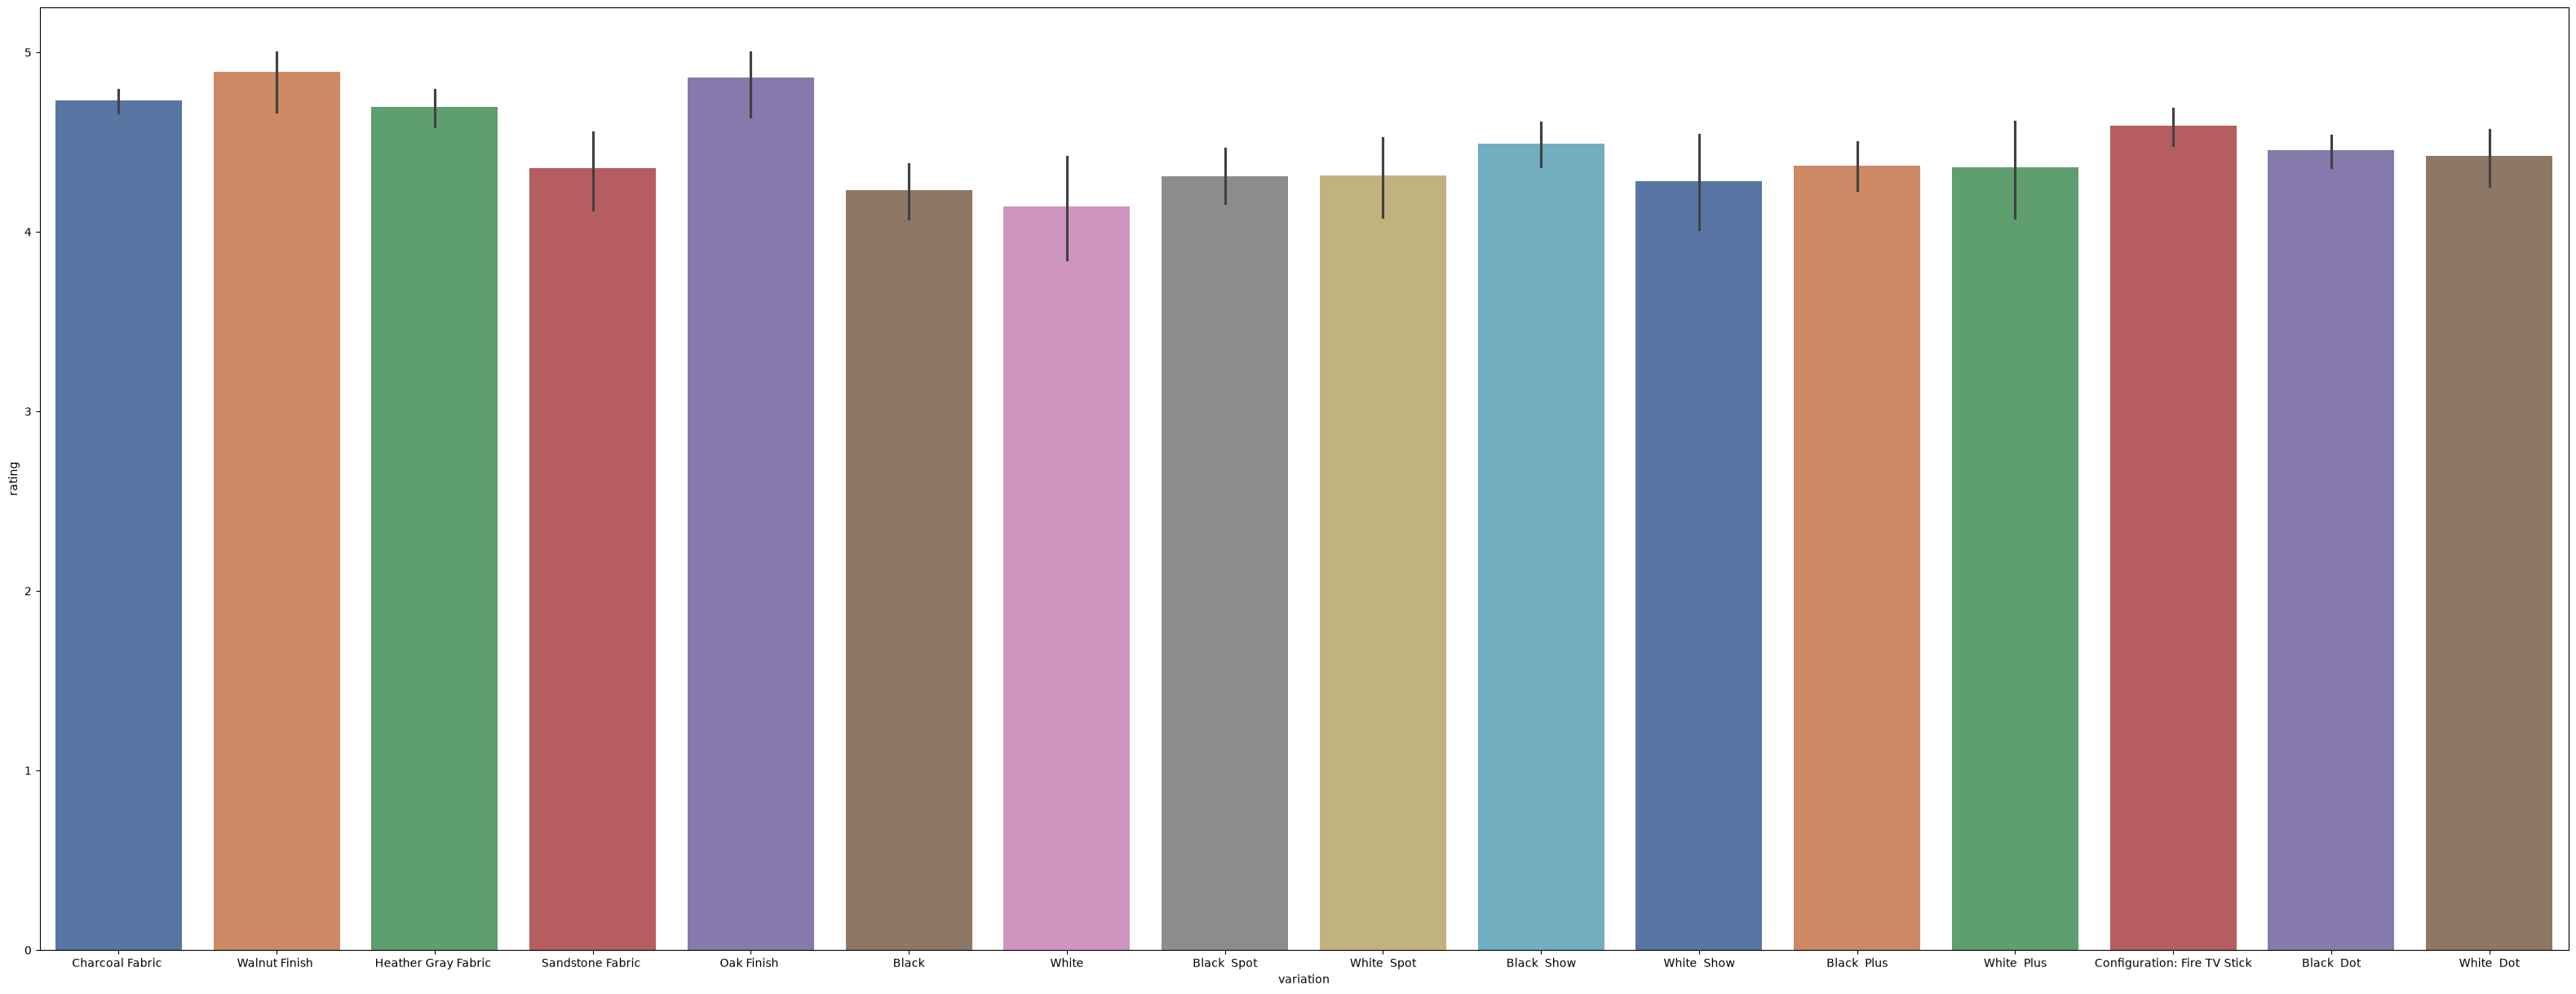

In [35]:
plt.figure(figsize=(40,15))
sns.barplot(x=df_alexa['variation'], y=df_alexa['rating'],palette='deep')
plt.show()

STEP 4 : Clean Up Data

In [36]:
df_alexa = df_alexa.drop(columns=['date', 'rating'], errors='ignore')
df_alexa

,variation,verified_reviews,feedback
0,Charcoal Fabric,Love my Echo!,1
1,Charcoal Fabric,Loved it!,1
2,Walnut Finish,"Sometimes while playing a game, you can answer...",1
3,Charcoal Fabric,I have had a lot of fun with this thing. My 4 ...,1
4,Charcoal Fabric,Music,1
...,...,...,...
3145,Black Dot,"Perfect for kids, adults and everyone in betwe...",1
3146,Black Dot,"Listening to music, searching locations, check...",1
3147,Black Dot,"I do love these things, i have them running my...",1
3148,White Dot,Only complaint I have is that the sound qualit...,1


In [37]:
variation_dummies = pd.get_dummies(df_alexa['variation'], drop_first = True)
variation_dummies

,Black Dot,Black Plus,Black Show,Black Spot,Charcoal Fabric,Configuration: Fire TV Stick,Heather Gray Fabric,Oak Finish,Sandstone Fabric,Walnut Finish,White,White Dot,White Plus,White Show,White Spot
0,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
3,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3146,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3147,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3148,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False


In [39]:
df_alexa = df_alexa.drop(columns=['variation'], errors='ignore')
df_alexa

,verified_reviews,feedback
0,Love my Echo!,1
1,Loved it!,1
2,"Sometimes while playing a game, you can answer...",1
3,I have had a lot of fun with this thing. My 4 ...,1
4,Music,1
...,...,...
3145,"Perfect for kids, adults and everyone in betwe...",1
3146,"Listening to music, searching locations, check...",1
3147,"I do love these things, i have them running my...",1
3148,Only complaint I have is that the sound qualit...,1


In [40]:
df_alexa = pd.concat([df_alexa, variation_dummies], axis=1)
df_alexa

,verified_reviews,feedback,Black Dot,Black Plus,Black Show,Black Spot,Charcoal Fabric,Configuration: Fire TV Stick,Heather Gray Fabric,Oak Finish,Sandstone Fabric,Walnut Finish,White,White Dot,White Plus,White Show,White Spot
0,Love my Echo!,1,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
1,Loved it!,1,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
2,"Sometimes while playing a game, you can answer...",1,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
3,I have had a lot of fun with this thing. My 4 ...,1,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
4,Music,1,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,"Perfect for kids, adults and everyone in betwe...",1,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3146,"Listening to music, searching locations, check...",1,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3147,"I do love these things, i have them running my...",1,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3148,Only complaint I have is that the sound qualit...,1,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False


Count Vectorization (Tokenization) Example

In [42]:
from sklearn.feature_extraction.text import CountVectorizer
sample_data = ["This is the first document", "This document is the second document", "And this is the third one", "Is this the First document?"]
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(sample_data)
print(X.toarray())

[[0 1 1 1 0 0 1 0 1]
 [0 2 0 1 0 1 1 0 1]
 [1 0 0 1 1 0 1 1 1]
 [0 1 1 1 0 0 1 0 1]]


In [43]:
print(vectorizer.get_feature_names_out())

['and' 'document' 'first' 'is' 'one' 'second' 'the' 'third' 'this']


In [47]:
vectorizer = CountVectorizer()
alexa_countvect = vectorizer.fit_transform(df_alexa['verified_reviews'].fillna(''))

In [48]:
alexa_countvect.shape

(3150, 4044)

In [49]:
print(vectorizer.get_feature_names_out())

['00' '000' '07' ... 'zzzz' 'zzzzzzz' 'útil']


In [50]:
print(alexa_countvect.toarray())

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [51]:
df_alexa = df_alexa.drop(columns=['verified_reviews'], errors='ignore')



In [53]:
reviews = pd.DataFrame(alexa_countvect.toarray())
df_alexa = pd.concat([df_alexa, reviews], axis=1)

In [54]:
df_alexa

,feedback,Black Dot,Black Plus,Black Show,Black Spot,Charcoal Fabric,Configuration: Fire TV Stick,Heather Gray Fabric,Oak Finish,Sandstone Fabric,...,4034,4035,4036,4037,4038,4039,4040,4041,4042,4043
0,1,False,False,False,False,True,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
1,1,False,False,False,False,True,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
2,1,False,False,False,False,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
3,1,False,False,False,False,True,False,False,False,False,...,0,1,0,0,0,0,0,0,0,0
4,1,False,False,False,False,True,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,1,True,False,False,False,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
3146,1,True,False,False,False,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
3147,1,True,False,False,False,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
3148,1,False,False,False,False,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0


In [55]:
X = df_alexa.drop(columns=['feedback'], errors='ignore')

In [58]:
X

,Black Dot,Black Plus,Black Show,Black Spot,Charcoal Fabric,Configuration: Fire TV Stick,Heather Gray Fabric,Oak Finish,Sandstone Fabric,Walnut Finish,...,4034,4035,4036,4037,4038,4039,4040,4041,4042,4043
0,False,False,False,False,True,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
1,False,False,False,False,True,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
2,False,False,False,False,False,False,False,False,False,True,...,0,0,0,0,0,0,0,0,0,0
3,False,False,False,False,True,False,False,False,False,False,...,0,1,0,0,0,0,0,0,0,0
4,False,False,False,False,True,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3145,True,False,False,False,False,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
3146,True,False,False,False,False,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
3147,True,False,False,False,False,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0
3148,False,False,False,False,False,False,False,False,False,False,...,0,0,0,0,0,0,0,0,0,0


In [56]:
Y = df_alexa['feedback']

In [57]:
Y

0       1
1       1
2       1
3       1
4       1
       ..
3145    1
3146    1
3147    1
3148    1
3149    1
Name: feedback, Length: 3150, dtype: int64

### STEP 4 : TRAIN THE MODEL

In [71]:
X.shape[1]

4059

In [60]:
Y.shape

(3150,)

In [80]:
from sklearn.model_selection import train_test_split
X = X.astype('float32')
Y = Y.astype('float32')
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2)

In [81]:
X_train.shape

(2520, 4059)

In [82]:
X_test.shape

(630, 4059)

In [66]:
Y_train.shape

(2520,)

In [68]:
Y_test.shape

(630,)

In [83]:
ANN_classifier = tf.keras.Sequential()
ANN_classifier.add(tf.keras.layers.Dense(units=400, activation='relu', input_shape=(X_train.shape[1],)))
ANN_classifier.add(tf.keras.layers.Dense(units=400, activation='relu'))
ANN_classifier.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))


c:\ML\.venv\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [84]:
ANN_classifier.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 400)            │     1,624,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 400)            │       160,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           401 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,784,801 (6.81 MB)

 Trainable params: 1,784,801 (6.81 MB)

 Non-trainable params: 0 (0.00 B)

In [85]:
ANN_classifier.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [86]:
epochs_hist = ANN_classifier.fit(X_train, Y_train, epochs=10, validation_split=0.2)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.9127 - loss: 0.2915 - val_accuracy: 0.9087 - val_loss: 0.1937
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9578 - loss: 0.0947 - val_accuracy: 0.9425 - val_loss: 0.1867
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9886 - loss: 0.0339 - val_accuracy: 0.9484 - val_loss: 0.2203
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9945 - loss: 0.0167 - val_accuracy: 0.9524 - val_loss: 0.3334
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9940 - loss: 0.0139 - val_accuracy: 0.9504 - val_loss: 0.3819
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9940 - loss: 0.0134 - val_accuracy: 0.9484 - val_loss: 0.4087
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9931 - loss: 0.0131 - val_accuracy: 0.9464 - val_loss: 0.4223
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9931 - loss: 0.0128 - val_accuracy: 0.9464 - v

In [ ]:
y_pred_train = ANN_classifier.predict(X_train)
y_pred_train

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


array([[0.99981594],
       [1.        ],
       [1.        ],
       ...,
       [0.99611783],
       [0.99999917],
       [1.        ]], shape=(2520, 1), dtype=float32)

In [89]:
y_pred_train = (y_pred_train > 0.5)

In [90]:
y_pred_train

array([[ True],
       [ True],
       [ True],
       ...,
       [ True],
       [ True],
       [ True]], shape=(2520, 1))

In [91]:
from sklearn.metrics import confusion_matrix
cm_train = confusion_matrix(Y_train, y_pred_train)
cm_train

array([[ 176,   32],
       [   4, 2308]])

<Axes: >

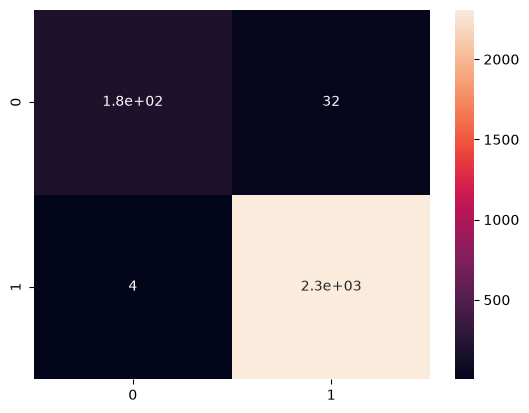

In [92]:
sns.heatmap(cm_train, annot=True)

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


<Axes: >

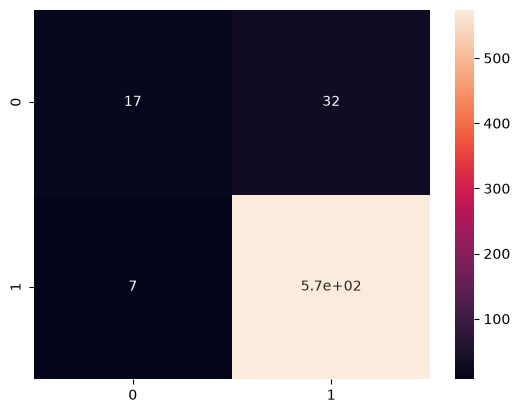

In [93]:
y_pred_test = ANN_classifier.predict(X_test)
y_pred_test = (y_pred_test > 0.5)
cm_test = confusion_matrix(Y_test, y_pred_test)

cm = confusion_matrix(Y_test, y_pred_test)
sns.heatmap(cm, annot=True)

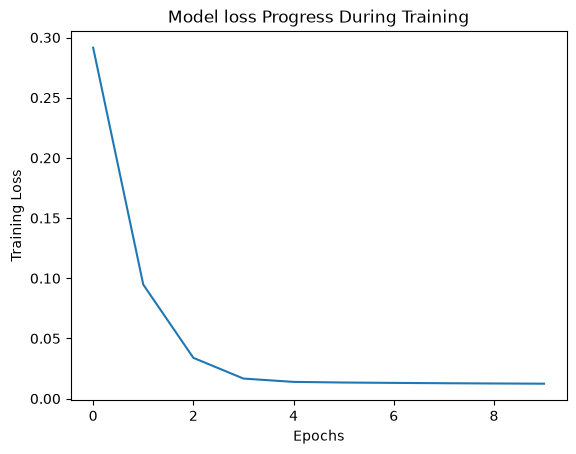

In [96]:
plt.plot(epochs_hist.history['loss'])
plt.title('Model loss Progress During Training')
plt.xlabel('Epochs')
plt.ylabel('Training Loss')
plt.show()

In [98]:
# Let's obtain a temporary storage directory
from pathlib import Path
Model_Directory = Path.cwd()
print(Model_Directory)

c:\ML\5 - DeepLearning


In [99]:
Version = 1

In [101]:
import os
export_path = os.path.join(Model_Directory, str(Version))
print(export_path)

c:\ML\5 - DeepLearning\1


In [103]:
ANN_classifier.export(export_path)

INFO:tensorflow:Assets written to: c:\ML\5 - DeepLearning\1\assets


INFO:tensorflow:Assets written to: c:\ML\5 - DeepLearning\1\assets


Saved artifact at 'c:\ML\5 - DeepLearning\1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 4059), dtype=tf.float32, name='keras_tensor_14')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  1483891320272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1483891325792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1483891325552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1483891320752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1483891317872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1483891326512: TensorSpec(shape=(), dtype=tf.resource, name=None)
